# 08 · DOE Eagle-I – recorded power outages (New York + New Jersey)

**Utility for the City Brain: high** · Domain: power · Incident types: `power_problem`

> Customers without power per county every 15 min: the shape, scale and slow recovery of real power problems, including Hurricane Ida.

| | |
|---|---|
| **Source** | US DOE / ORNL Eagle-I, figshare DOI 10.6084/m9.figshare.24237376 (2021 file) |
| **Licence** | CC BY 4.0 (cite the figshare DOI) |
| **In this repo** | Sample: NY + NJ, 15 Aug – 15 Sep 2021 (`data/power/eaglei-outages/nynj_aug_sep_2021.csv.gz`) |
| **Get it** | https://doi.org/10.6084/m9.figshare.24237376 (download `eaglei_outages_2021.csv`, 1.1 GB, then filter the states) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

| Column | Meaning |
|---|---|
| `fips_code`, `county`, `state` | County |
| `customers_out` | Customers without power in that county |
| `run_start_time` | 15-minute time step (as provided; likely UTC) |

In [2]:
e = pd.read_csv(path('power/eaglei-outages/nynj_aug_sep_2021.csv.gz'), parse_dates=['run_start_time'])
print(f"{len(e):,} rows · {e.county.nunique()} counties"); e.head()

118,703 rows · 81 counties


,fips_code,county,state,customers_out,run_start_time
0,34003,Bergen,New Jersey,7.0,2021-08-15
1,34005,Burlington,New Jersey,4.0,2021-08-15
2,34007,Camden,New Jersey,4.0,2021-08-15
3,34009,Cape May,New Jersey,22.0,2021-08-15
4,34013,Essex,New Jersey,49.0,2021-08-15


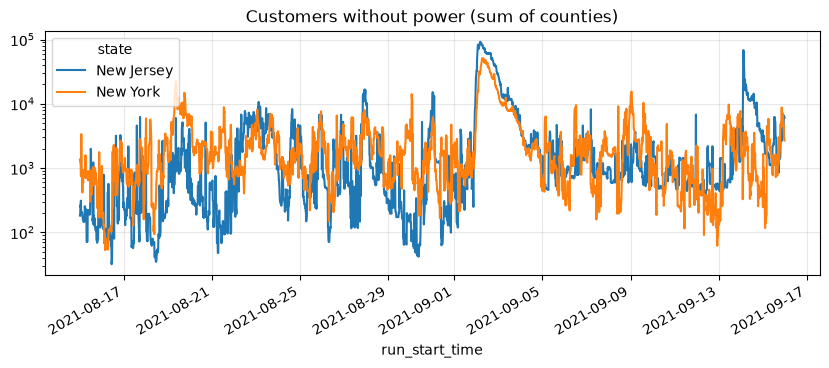

,baseline (median before 1 Sep),Ida peak,peak time
state,,,
New Jersey,437.0,92651.0,2021-09-02 04:15:00
New York,1483.0,50995.0,2021-09-02 07:15:00


In [3]:
tot = e.pivot_table(index='run_start_time', columns='state', values='customers_out', aggfunc='sum').fillna(0)
ax = tot.plot(title='Customers without power (sum of counties)', logy=True); plt.show()
base = tot.loc[:'2021-08-31'].median()
pd.DataFrame({'baseline (median before 1 Sep)': base, 'Ida peak': tot.loc['2021-09-01':'2021-09-04'].max(),
              'peak time': tot.loc['2021-09-01':'2021-09-04'].idxmax()})

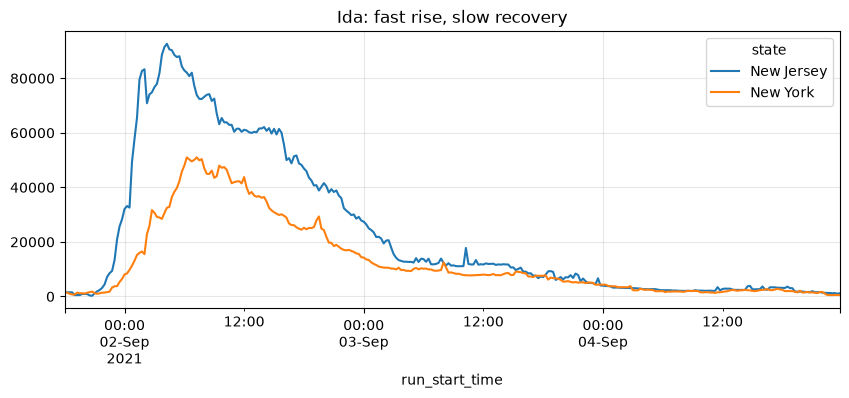

county peak
state      county                  
New Jersey Essex            25768.0
New York   Westchester      18475.0
New Jersey Morris           12038.0
           Sussex           12008.0
           Somerset         10196.0
New York   Suffolk           9343.0
           Orange            8295.0
New Jersey Bergen            8254.0

In [4]:
ida = tot.loc['2021-09-01 18:00':'2021-09-04']
ida.plot(title='Ida: fast rise, slow recovery'); plt.show()
peak_t = e[e.run_start_time.between('2021-09-02', '2021-09-03')].groupby(['state', 'county']).customers_out.max()
peak_t.sort_values(ascending=False).head(8).to_frame('county peak')

Somerset County (NJ) is where the Raritan gauge is (notebook 03): record river flood and thousands of customers out the same night, a real **flood → power** chain. Recovery takes more than a day.

## 2. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | `power_problem` = customers out (or load drop) ≥ 10 × the normal level, sustained ≥ 30 min; expect slow recovery (don't close too early) |
| **Scenarios** | Storm night (flood + outage), and other 2021 events give "power problem without flood" |
| **Graph** | County / zone → outage incident, linked to the flood incident through `correlation_id` / `/chain` |
| **Mock** | Real outage curve for a `power_problem` reported by the grid operator |

**Limits:** county level, customers not kW; time zone as provided.